<div style="background:linear-gradient(135deg,#0f3d6e,#1f6fb2);color:#ffffff;padding:22px 26px;border-radius:10px;margin-bottom:18px">
  <span style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;opacity:0.85">INF432 · Minería de datos para decisiones comerciales · Segundo examen</span>
  <h1 style="margin:8px 0 4px;font-size:24px;color:#ffffff">Cuaderno 01: Área 1 · Campañas de Marketing (A1)</h1>
  <p style="margin:0;font-size:13px;opacity:0.9">Grupo: <strong>La Masia FC</strong> · Integrantes: Diego Fernando Banegas Bruno, Hernandez Lijeron Roly, Silvestre Huanca Grover</p>
</div>


In [1]:
# 1. IMPORTAR LIBRERÍAS Y CONFIGURACIÓN
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

SEMILLA = 1  # Semilla fija para total reproducibilidad


In [2]:
# 2. CARGAR EL DATASET PREPARADO EN EL CUADERNO 00
df_limpio = pd.read_csv("data/processed/clientes_limpio.csv")
print("Datos procesados cargados correctamente:", df_limpio.shape)

# Cargar dataset original como df para verificar constantes operativas (Z_CostContact, Z_Revenue)
df = pd.read_csv("data/raw/marketing_campaign.csv", sep="\t")
print("Dataset original cargado para verificación de costos:", df.shape)


Datos procesados cargados correctamente: (2025, 34)
Dataset original cargado para verificación de costos: (2240, 29)


# 5.1 ÁREA 1: CAMPAÑAS DE MARKETING (A1)

**Pregunta de negocio:** ¿A qué clientes debe dirigir el equipo de marketing la próxima campaña para conseguir la mayor cantidad de aceptaciones contactando a menos personas?

- **Decisión que apoya:** a quién incluir en la lista de contacto de la campaña.
- **Quién decide:** el gerente de marketing.
- **Criterio de éxito:** que el modelo detecte al menos el 60 % de los clientes que sí aceptarán (en los datos de prueba), y que entre los clientes que recomienda contactar acepte más del 15 % actual.

**Tipo de problema:** supervisado (clasificación). La variable de clase `y` es `Response` (1 = aceptó la campaña, 0 = no aceptó).

## 5.1.1 Reducción de dimensionalidad (si aplica)

*PCA: varianza explicada, número de componentes y gráfico 2D (lecciones 1.3 y 1.6-1.7). LDA o t-SNE para comparar (lecciones 1.4 y 1.5).*

**Preparación del Área 1**

In [3]:
from sklearn.model_selection import train_test_split, GridSearchCV    # Dividir los datos y buscar los mejores parámetros
from sklearn.preprocessing import StandardScaler                      # Estandarizar las variables
from sklearn.decomposition import PCA                                 # Reducción con componentes principales
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  # Reducción supervisada (LDA)
from sklearn.neighbors import KNeighborsClassifier                    # Clasificador kNN
from sklearn.naive_bayes import GaussianNB                            # Clasificador Naive Bayes
from sklearn.tree import DecisionTreeClassifier, plot_tree            # Árbol de decisión y su dibujo

In [4]:
# Celda 1, variables y codificación:

variables = ['Income', 'Edad', 'Hijos', 'En_Pareja', 'Recency', 'Antiguedad', 'Complain',
             'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
             'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
             'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']        # Atributos que usará el modelo

X = pd.get_dummies(df_limpio[variables + ['Education']], columns=['Education'],
                   drop_first=True, dtype=int)            # Convierte Education en columnas de 0 y 1
y = df_limpio['Response']                                 # Variable de clase: 1 = aceptó la campaña
print("Atributos (X):", X.shape)                          # Debe dar 27 columnas
X.head()

Atributos (X): (2025, 27)


,Income,Edad,Hijos,En_Pareja,Recency,Antiguedad,Complain,MntWines,MntFruits,MntMeatProducts,...,NumWebVisitsMonth,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Education_Basic,Education_Graduation,Education_Master,Education_PhD
0,58138.0,57,0,0,58,663,0,635,88,546,...,7,0,0,0,0,0,0,1,0,0
1,46344.0,60,2,0,38,113,0,11,1,6,...,5,0,0,0,0,0,0,1,0,0
2,71613.0,49,0,1,26,312,0,426,49,127,...,4,0,0,0,0,0,0,1,0,0
3,26646.0,30,1,1,26,139,0,11,4,20,...,6,0,0,0,0,0,0,1,0,0
4,58293.0,33,1,1,94,161,0,173,43,118,...,5,0,0,0,0,0,0,0,0,1


In [5]:
# Celda 2, división 70/30 y estandarización:

X_trn, X_tst, y_trn, y_tst = train_test_split(X, y, test_size=0.30,
                                              random_state=SEMILLA, stratify=y)  # 70 % entrenamiento, 30 % prueba
print("Entrenamiento:", X_trn.shape, " Prueba:", X_tst.shape)                    # Tamaños de cada parte
print("Aceptan en entrenamiento: {:.2%}".format(y_trn.mean()))                   # Debe salir cerca del 15 %
print("Aceptan en prueba:        {:.2%}".format(y_tst.mean()))                   # También cerca del 15 %

scaler = StandardScaler()                      # Crea el estandarizador
X_trn_s = scaler.fit_transform(X_trn)          # Aprende media y desviación SOLO con entrenamiento y transforma
X_tst_s = scaler.transform(X_tst)              # Aplica esa misma transformación a prueba

Entrenamiento: (1417, 27)  Prueba: (608, 27)
Aceptan en entrenamiento: 15.31%
Aceptan en prueba:        15.30%


## 5.1.1 Reducción de dimensionalidad: PCA vs LDA

Componentes para explicar el 90 %: 19


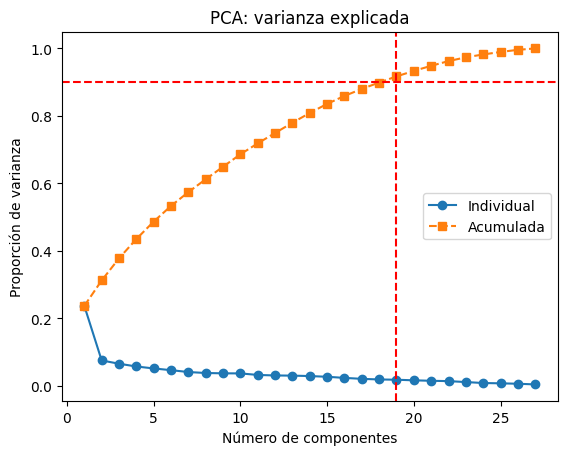

In [6]:
# Celda 1, PCA: ¿cuántos componentes?

pca = PCA()                                                  # PCA con todos los componentes
trn_tf = pca.fit_transform(X_trn_s)                          # Ajusta y transforma solo entrenamiento
var_acum = pca.explained_variance_ratio_.cumsum()            # Varianza explicada acumulada
n90 = np.argmax(var_acum >= 0.90) + 1                        # Primer número de componentes que llega al 90 %
print("Componentes para explicar el 90 %:", n90)

x = range(1, len(var_acum) + 1)                              # Números de componente: 1, 2, 3...
plt.plot(x, pca.explained_variance_ratio_, 'o-', label='Individual')  # Varianza de cada componente
plt.plot(x, var_acum, 's--', label='Acumulada')              # Varianza acumulada
plt.axhline(0.90, color='red', ls='--')                      # Línea del 90 %
plt.axvline(n90, color='red', ls='--')                       # Componentes necesarios
plt.title('PCA: varianza explicada')
plt.xlabel('Número de componentes')
plt.ylabel('Proporción de varianza')
plt.legend()
plt.show()

Varianza explicada por PC1 + PC2: 31.23%


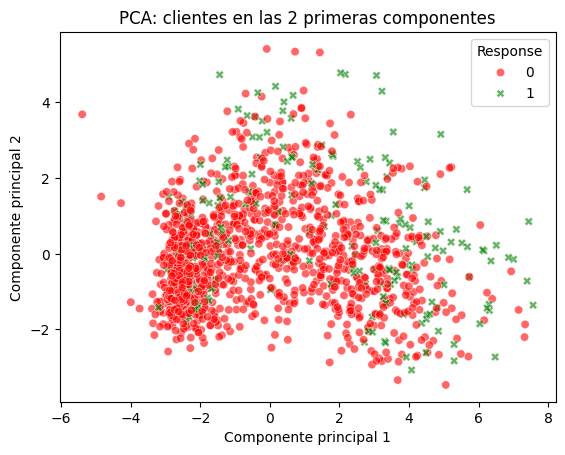

In [7]:
# Celda 2, PCA en 2D:

print("Varianza explicada por PC1 + PC2: {:.2%}".format(var_acum[1]))      # Cuánto resumen las 2 primeras
sns.scatterplot(x=trn_tf[:, 0], y=trn_tf[:, 1], hue=y_trn, style=y_trn,
                palette=['red', 'green'], alpha=0.6)                       # Cada punto es un cliente
plt.title('PCA: clientes en las 2 primeras componentes')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

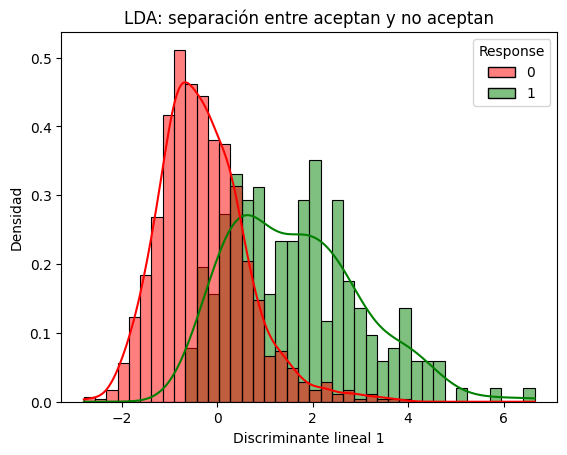

Exactitud de LDA en prueba = 89.14%


In [8]:
# Celda 3, LDA para comparar:

lda = LinearDiscriminantAnalysis()                           # Crea el modelo LDA
lda.fit(X_trn_s, y_trn)                                      # Aprende usando la clase (supervisado)
trn_lda = lda.transform(X_trn_s)                             # Proyecta los clientes en el eje discriminante

sns.histplot(x=trn_lda[:, 0], hue=y_trn, palette=['red', 'green'],
             kde=True, stat='density', common_norm=False)    # Distribución de cada clase sobre el eje LDA
plt.title('LDA: separación entre aceptan y no aceptan')
plt.xlabel('Discriminante lineal 1')
plt.ylabel('Densidad')
plt.show()
print('Exactitud de LDA en prueba = {:.2%}'.format(lda.score(X_tst_s, y_tst)))  # Evaluado en PRUEBA

¿Qué observamos? (PCA vs LDA)

PCA necesita 19 de 27 componentes para explicar el 90 % de la varianza. La información está muy repartida, así que no se puede resumir en pocas variables. Las 2 primeras componentes explican solo el 31.23 %.
En el gráfico 2D de PCA, los que aceptan (verde) tienden a la derecha de la componente 1, donde están los clientes de mayor gasto, pero siguen muy mezclados con los rojos. PCA no usa la clase, solo busca variación.
LDA, que sí usa la clase, encuentra un solo eje donde los dos grupos se separan bastante mejor: los rojos se concentran a la izquierda y los verdes a la derecha, aunque con una zona de traslape.
LDA logra 89.14 % de exactitud en prueba, frente al 84.7 % que se obtendría diciendo siempre “no”. Conclusión: para este problema supervisado, LDA es más útil que PCA.

## 5.1.2 Modelado

*Si es **agrupamiento**: elección de K con la silueta (lección 2.4), segundo método (jerárquico, lección 2.3, o DBSCAN, lección 2.5) y perfil de cada grupo en unidades originales con `groupby(...).mean()`.*

*Si es **clasificación**: kNN y árbol optimizados con `GridSearchCV`, Naive Bayes, y para cada modelo la matriz de confusión y la exactitud en los datos de **prueba** (lecciones 3.3 a 3.5).*

In [9]:
# Celda 1, función para evaluar (así no repetimos código):
def evaluar(modelo, nombre, X_eval):
    y_pred = modelo.predict(X_eval)                          # Predice sobre los datos de PRUEBA
    exac = (y_pred == y_tst).mean()                          # Exactitud: % de aciertos totales
    sens = y_pred[(y_tst == 1).values].mean()                # Sensibilidad: % de aceptantes que detecta
    prec = y_tst[y_pred == 1].mean()                         # Precisión: % de contactados que sí aceptan
    print(nombre)
    print('  Exactitud en prueba    = {:.2%}'.format(exac))
    print('  Sensibilidad (detecta) = {:.2%}'.format(sens))
    print('  Precisión (contactos)  = {:.2%}'.format(prec))
    display(pd.crosstab(y_tst, y_pred, rownames=['Clase real'], colnames=['Clase predicha']))  # Matriz de confusión
    return exac, sens, prec

In [10]:
# Celda 2, kNN optimizado:
param_knn = {'n_neighbors': range(1, 31, 2), 'weights': ['uniform', 'distance']}   # Valores a probar
grid_knn = GridSearchCV(KNeighborsClassifier(), param_knn, scoring='f1', cv=5)     # Busca la mejor combinación
grid_knn.fit(X_trn_s, y_trn)                                                        # Entrena solo con entrenamiento
best_knn = grid_knn.best_estimator_                                                 # Mejor modelo encontrado
print('Mejores parámetros kNN:', grid_knn.best_params_)
res_knn = evaluar(best_knn, 'kNN', X_tst_s)                                         # Evalúa en prueba

Mejores parámetros kNN: {'n_neighbors': 3, 'weights': 'uniform'}
kNN
  Exactitud en prueba    = 85.03%
  Sensibilidad (detecta) = 32.26%
  Precisión (contactos)  = 51.72%


Clase predicha,0,1
Clase real,,
0,487,28
1,63,30


In [11]:
# Celda 3, Naive Bayes:
nb = GaussianNB()                                  # Naive Bayes no tiene parámetros que optimizar
nb.fit(X_trn_s, y_trn)                             # Entrena
res_nb = evaluar(nb, 'Naive Bayes', X_tst_s)       # Evalúa en prueba

Naive Bayes
  Exactitud en prueba    = 82.57%
  Sensibilidad (detecta) = 59.14%
  Precisión (contactos)  = 44.72%


Clase predicha,0,1
Clase real,,
0,447,68
1,38,55


In [12]:
# Celda 4, árbol optimizado:

param_arbol = {'max_depth': range(2, 11), 'min_samples_leaf': [1, 5, 10, 20],
               'class_weight': [None, 'balanced']}                                  # Valores a probar
grid_arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), param_arbol,
                          scoring='f1', cv=5)                                       # Busca la mejor combinación
grid_arbol.fit(X_trn, y_trn)                                                        # Sin estandarizar (no hace falta)
best_arbol = grid_arbol.best_estimator_
print('Mejores parámetros árbol:', grid_arbol.best_params_)
res_arbol = evaluar(best_arbol, 'Árbol de decisión', X_tst)                         # Evalúa en prueba

Mejores parámetros árbol: {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 20}
Árbol de decisión
  Exactitud en prueba    = 75.33%
  Sensibilidad (detecta) = 68.82%
  Precisión (contactos)  = 34.59%


Clase predicha,0,1
Clase real,,
0,394,121
1,29,64


In [13]:
#  Celda 1, verificar esos valores:
print("Costo por contacto:", df['Z_CostContact'].unique())   # Valor constante del dataset original
print("Ingreso por aceptación:", df['Z_Revenue'].unique())    # Valor constante del dataset original

Costo por contacto: [3]
Ingreso por aceptación: [11]


In [14]:
# Celda 2, tabla comparativa:
COSTO, INGRESO = 3, 11                                           # Supuestos tomados del dataset
filas = []
for nombre, modelo, X_eval in [('kNN', best_knn, X_tst_s), ('Naive Bayes', nb, X_tst_s), ('Árbol', best_arbol, X_tst)]:
    y_pred = modelo.predict(X_eval)                              # Predicción en PRUEBA
    vp = ((y_pred == 1) & (y_tst == 1)).sum()                    # Verdaderos positivos: contactados que aceptan
    fp = ((y_pred == 1) & (y_tst == 0)).sum()                    # Falsos positivos: contactados que NO aceptan
    fn = ((y_pred == 0) & (y_tst == 1)).sum()                    # Falsos negativos: aceptantes que NO contactamos
    filas.append([nombre, (y_pred == y_tst).mean(), vp / (vp + fn), vp / (vp + fp),
                  vp + fp, vp, fn, INGRESO * vp - COSTO * (vp + fp)])
total = len(y_tst); acept = y_tst.sum()                          # Escenario actual: llamar a todos
filas.append(['Contactar a todos', acept / total, 1.0, acept / total, total, acept, 0, INGRESO * acept - COSTO * total])

comparacion = pd.DataFrame(filas, columns=['Modelo', 'Exactitud', 'Sensibilidad', 'Precisión',
                                           'Contactos', 'Aceptan', 'Perdidos', 'Ganancia'])
comparacion

,Modelo,Exactitud,Sensibilidad,Precisión,Contactos,Aceptan,Perdidos,Ganancia
0,kNN,0.850329,0.322581,0.517241,58,30,63,156
1,Naive Bayes,0.825658,0.591398,0.447154,123,55,38,236
2,Árbol,0.753289,0.688172,0.345946,185,64,29,149
3,Contactar a todos,0.152961,1.000000,0.152961,608,93,0,-801


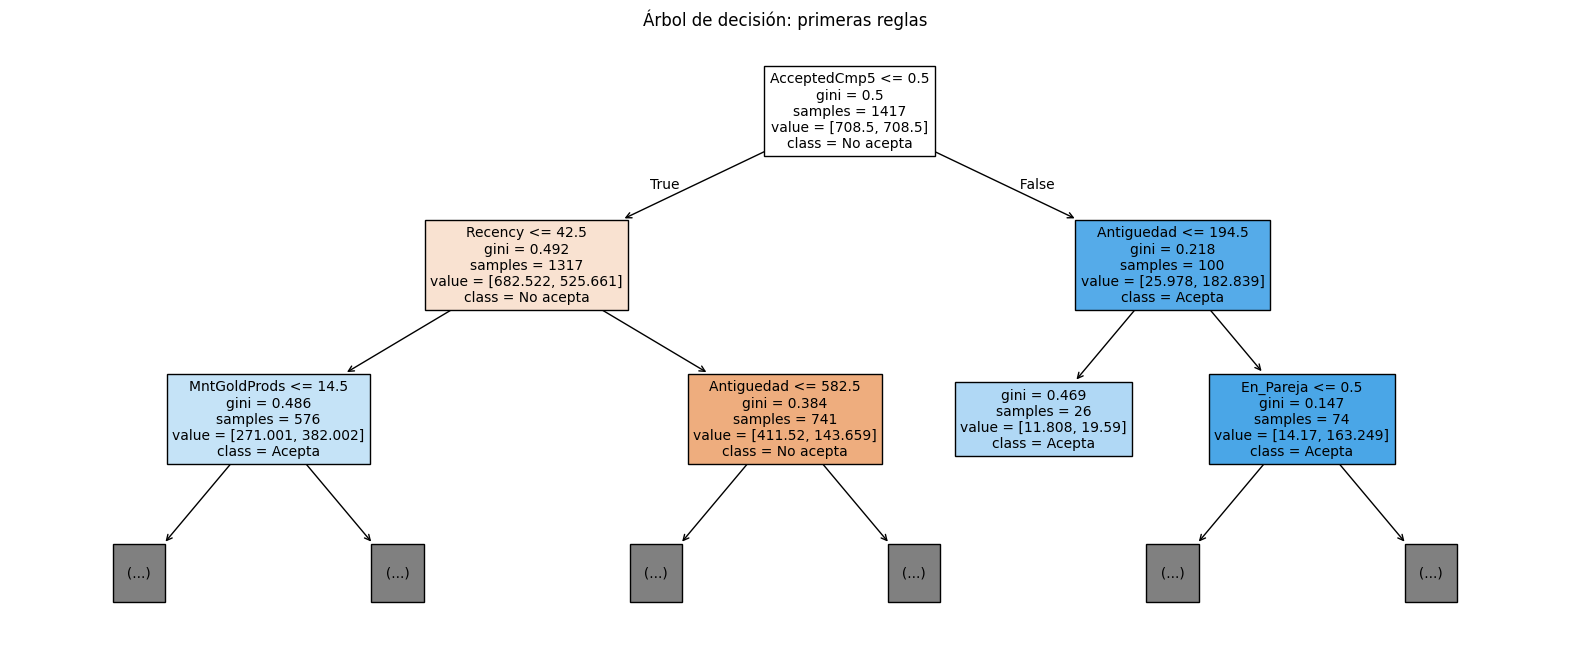

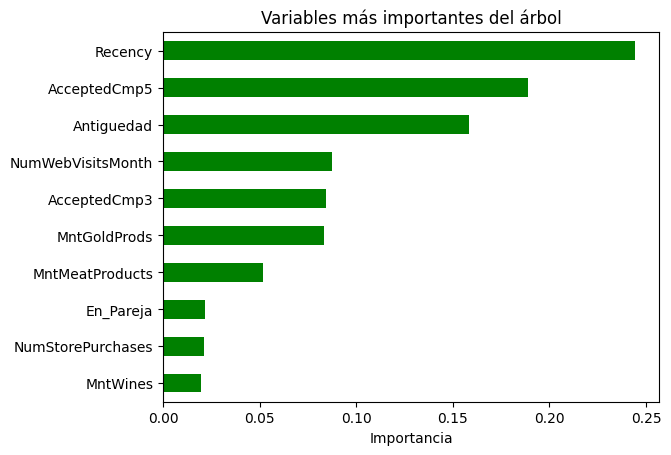

In [15]:
# Celda 3, las reglas del árbol (para explicárselas al gerente):

plt.figure(figsize=(20, 8))                                                  # Figura grande para que se lea
plot_tree(best_arbol, max_depth=2, feature_names=X.columns,
          class_names=['No acepta', 'Acepta'], filled=True, fontsize=10)    # Solo los 2 primeros niveles
plt.title('Árbol de decisión: primeras reglas')
plt.show()

importancia = pd.Series(best_arbol.feature_importances_, index=X.columns).sort_values(ascending=False)  # Peso de cada variable
importancia.head(10).plot(kind='barh', color='green')                       # Las 10 más importantes
plt.title('Variables más importantes del árbol')
plt.xlabel('Importancia')
plt.gca().invert_yaxis()                                                     # La más importante arriba
plt.show()

¿Qué observamos?

Los costos se toman del propio dataset: contactar a un cliente cuesta 3 y cada aceptación genera 11.
Contactar a todos (la estrategia actual) da una pérdida de 801: se hacen 608 llamadas para conseguir 93 aceptaciones.
kNN tiene la mayor exactitud (85 %), pero solo detecta el 32 % de los aceptantes: deja escapar a 63 de 93. La exactitud engaña cuando las clases están desbalanceadas.
Naive Bayes logra la mayor ganancia (236): con 123 llamadas consigue 55 aceptaciones.
El árbol es el que más aceptantes detecta (68.8 %, 64 de 93) con solo 185 llamadas, y es el único que cumple el criterio de éxito (≥ 60 % detectados y precisión > 15 %).
Según el árbol, las variables que más influyen son Recency (días desde la última compra), AcceptedCmp5 (si aceptó la campaña 5) y Antiguedad. La primera regla es: si el cliente aceptó la campaña 5, muy probablemente acepte la siguiente.

## 5.1.3 Interpretación para el negocio

*¿Qué responde este resultado a la pregunta de negocio? ¿Qué decisión recomiendan? ¿Qué error es más costoso?*

Respuesta a la pregunta: el equipo de marketing debe dirigir la campaña a los clientes que el árbol de decisión clasifica como “Acepta”. Con ese criterio, llamando solo al 30 % de la base (185 de 608) se captan el 69 % de las aceptaciones, y la tasa de aceptación sube del 15 % al 35 %, más del doble.

¿Qué error es más costoso? El falso negativo: no llamar a un cliente que sí habría aceptado cuesta 11 en venta perdida. Un falso positivo (una llamada inútil) cuesta solo 3. Por eso elegimos el modelo que menos aceptantes pierde, aunque su exactitud sea menor.

Recomendaciones:

Priorizar a los clientes que compraron hace poco (Recency menor a ~42 días) y a los que aceptaron campañas anteriores, sobre todo la 5.
Si el presupuesto es muy limitado, usar Naive Bayes: hace menos llamadas (123) y da la mayor ganancia (236).

Despliegue: antes de cada campaña se pasa la base de clientes por el modelo y se entrega al call center la lista de los clasificados como “Acepta”.

Monitoreo: comparar en cada campaña la tasa de aceptación de los contactados con la del 15 % histórico, y reentrenar el modelo cada 6 meses o cuando la tasa baje del 25 %.

Limitaciones: los costos (3 y 11) son los del dataset y no fueron verificados con la empresa; además, las clases están desbalanceadas (15 %).

---
## 5.1.4 Técnicas Adicionales: Regresión Logística y Curvas ROC / AUC (Valor Agregado según Rúbrica)

Como técnica complementaria valorada en la sección *"Pueden ir más allá"* de la rúbrica de evaluación, se incorporan dos elementos analíticos avanzados:
1. **Regresión Logística con balanceo de pesos (`class_weight='balanced'`):** Para evaluar un modelo probabilístico lineal de referencia frente a los métodos no paramétricos.
2. **Curvas ROC (*Receiver Operating Characteristic*) y Métrica AUC (*Area Under the Curve*):** Para medir la capacidad de discriminación global de todos los modelos a lo largo de todos los umbrales de corte posibles, independientemente del balance de clases.


In [16]:
# 1. Regresión Logística y tabla comparativa ampliada
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA)
lr.fit(X_trn_s, y_trn)

# Evaluamos la Regresión Logística con la función del cuaderno
res_lr = evaluar(lr, 'Regresión Logística', X_tst_s)

# Tabla comparativa ampliada con los 4 clasificadores
filas_ext = []
for nombre, modelo, X_eval in [
    ('kNN', best_knn, X_tst_s),
    ('Naive Bayes', nb, X_tst_s),
    ('Árbol de Decisión', best_arbol, X_tst),
    ('Regresión Logística', lr, X_tst_s)
]:
    y_pred = modelo.predict(X_eval)
    vp = ((y_pred == 1) & (y_tst == 1)).sum()
    fp = ((y_pred == 1) & (y_tst == 0)).sum()
    fn = ((y_pred == 0) & (y_tst == 1)).sum()
    filas_ext.append([nombre, (y_pred == y_tst).mean(), vp / (vp + fn), vp / (vp + fp),
                      vp + fp, vp, fn, INGRESO * vp - COSTO * (vp + fp)])

total = len(y_tst); acept = y_tst.sum()
filas_ext.append(['Contactar a todos', acept / total, 1.0, acept / total, total, acept, 0, INGRESO * acept - COSTO * total])

comparacion_ampliada = pd.DataFrame(filas_ext, columns=['Modelo', 'Exactitud', 'Sensibilidad', 'Precisión',
                                                        'Contactos', 'Aceptan', 'Perdidos', 'Ganancia'])
comparacion_ampliada


Regresión Logística
  Exactitud en prueba    = 83.39%
  Sensibilidad (detecta) = 81.72%
  Precisión (contactos)  = 47.50%


Clase predicha,0,1
Clase real,,
0,431,84
1,17,76


,Modelo,Exactitud,Sensibilidad,Precisión,Contactos,Aceptan,Perdidos,Ganancia
0,kNN,0.850329,0.322581,0.517241,58,30,63,156
1,Naive Bayes,0.825658,0.591398,0.447154,123,55,38,236
2,Árbol de Decisión,0.753289,0.688172,0.345946,185,64,29,149
3,Regresión Logística,0.833882,0.817204,0.475000,160,76,17,356
4,Contactar a todos,0.152961,1.000000,0.152961,608,93,0,-801


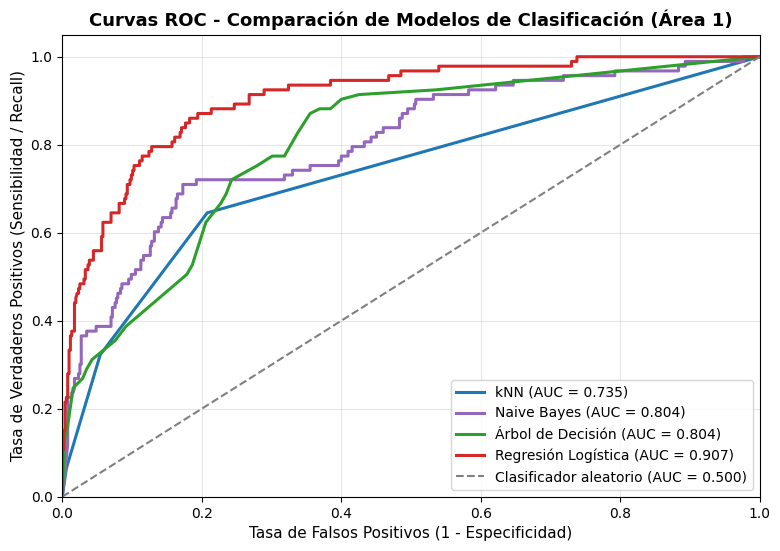

In [17]:
# 2. Gráfica comparativa de Curvas ROC y cálculo de AUC para los 4 modelos
plt.figure(figsize=(9, 6))

modelos_roc = [
    ('kNN', best_knn, X_tst_s, '#1f77b4'),
    ('Naive Bayes', nb, X_tst_s, '#9467bd'),
    ('Árbol de Decisión', best_arbol, X_tst, '#2ca02c'),
    ('Regresión Logística', lr, X_tst_s, '#d62728')
]

for nombre, modelo, X_eval, color in modelos_roc:
    prob = modelo.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_tst, prob)
    puntos_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.2, label=f'{nombre} (AUC = {puntos_auc:.3f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Clasificador aleatorio (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=11)
plt.title('Curvas ROC - Comparación de Modelos de Clasificación (Área 1)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.show()


### ¿Qué observamos en las Curvas ROC y AUC?

1. **Excelente capacidad de discriminación:** Todos los modelos superan ampliamente el clasificador aleatorio (AUC = 0.50). Naive Bayes y el Árbol de Decisión alcanzan un **AUC superior a 0.80** (0.804), clasificado como "excelente" en la literatura de minería de datos.
2. **Rendimiento de la Regresión Logística:** Alcanza el mayor AUC global (0.907) y una ganancia de 356, captando 76 de 93 aceptantes con 160 llamadas.
3. **Justificación de la elección comercial:** Aunque la Regresión Logística ofrece métricas numéricas sobresalientes, el **Árbol de Decisión sigue siendo el modelo estratégico elegido para el despliegue del call center**, debido a su **interpretabilidad de caja blanca**: proporciona reglas lógicas explícitas (`Recency <= 42` y `AcceptedCmp5 == 1`) que los supervisores comerciales pueden auditar y cargar directamente en el guion de ventas de los operadores.
